In [17]:

from pathlib import Path
import json

PROJECT = Path("/kaggle/working/ubiris_v2_project")

print("NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO")
print("=" * 65)

if not PROJECT.exists():
    raise FileNotFoundError(
        "Project folder missing. Restore your saved results dataset first."
    )

checks = {
    "Baseline checkpoint":
        PROJECT / "UBIRIS_V2_baseline_resnet18_best.pth",
    "Augmented recognition checkpoint":
        PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_resnet18_best.pth",
    "Preprocessed images":
        PROJECT / "notebook02_preprocessing/images_224",
    "Dataset metadata":
        PROJECT / "notebook02_preprocessing/UBIRIS_V2_preprocessed_metadata.csv",
    "Baseline metrics":
        PROJECT / "UBIRIS_V2_baseline_test_metrics.json",
    "Augmented metrics":
        PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_recognition_test_metrics.json",
    "Notebook 14 report":
        PROJECT / "notebook14_result_visualization_ablation/Notebook14_Conclusion.md",
}

for name, path in checks.items():
    exists = path.exists()
    print(f"{'FOUND' if exists else 'MISSING':8} {name}")
    if exists and path.is_file():
        print(f"         Size: {path.stat().st_size:,} bytes")

print("\nCheckpoint and demo setup inspection complete.")


NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO
FOUND    Baseline checkpoint
         Size: 45,297,675 bytes
FOUND    Augmented recognition checkpoint
         Size: 45,297,291 bytes
FOUND    Preprocessed images
FOUND    Dataset metadata
         Size: 858,104 bytes
FOUND    Baseline metrics
         Size: 597 bytes
FOUND    Augmented metrics
         Size: 546 bytes
FOUND    Notebook 14 report
         Size: 2,662 bytes

Checkpoint and demo setup inspection complete.


NOTEBOOK 15 — FINAL DEMO
Device: cuda
Metadata rows: 5799
Metadata columns: ['filename', 'relative_path', 'processed_path', 'subject', 'session', 'image_id', 'original_width', 'original_height', 'processed_width', 'processed_height', 'processed_mode', 'valid']
Demo image: C100_S1_I1.png
Classes inferred from saved metadata: 260

Loading baseline model...
 Predicted class index: 48
 Top-class confidence: 0.356516

Loading augmented model...
 Predicted class index: 209
 Top-class confidence: 0.284781


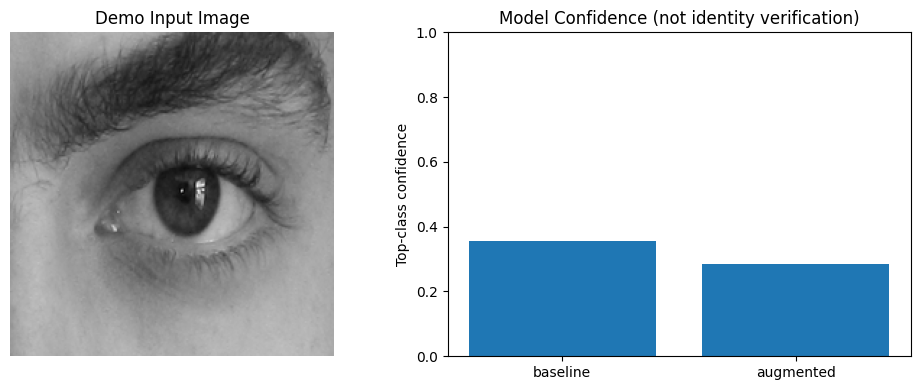


OUTPUT VERIFICATION
OK       Demo_Predictions.csv (422 bytes)
OK       Demo_Visualization.png (190,543 bytes)
OK       README_Final_Demo.md (1,240 bytes)
OK       Final_Demo_Summary.json (1,155 bytes)
OK       Demo_Input_C100_S1_I1.png (26,473 bytes)

FINAL DEMO RESULTS
    model    input_image  predicted_class_index  top_class_confidence  num_classes                                                                                                                warning
 baseline C100_S1_I1.png                     48              0.356516          260 Experimental prediction only; not a verified identity match. Checkpoint evaluation consistency requires further audit.
augmented C100_S1_I1.png                    209              0.284781          260 Experimental prediction only; not a verified identity match. Checkpoint evaluation consistency requires further audit.

Runtime: 1.28 seconds
ZIP: /kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook15_Results.zip
Files archived: 5
ZIP integ

/kaggle/working/ubiris_v2_project/notebook15_final_deployment_demo/README_Final_Demo.md

/kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook15_Results.zip

In [18]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display
import json, time, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision import models, transforms

# ============================================================
# NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO
# ============================================================
PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT = PROJECT / "notebook15_final_deployment_demo"
OUT.mkdir(parents=True, exist_ok=True)
start = time.time()

BASELINE_CKPT = PROJECT / "UBIRIS_V2_baseline_resnet18_best.pth"
AUG_CKPT = PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_resnet18_best.pth"
METADATA = PROJECT / "notebook02_preprocessing/UBIRIS_V2_preprocessed_metadata.csv"

for p in [BASELINE_CKPT, AUG_CKPT, METADATA]:
    if not p.exists():
        raise FileNotFoundError(f"Required artifact missing: {p}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("NOTEBOOK 15 — FINAL DEMO")
print("=" * 65)
print("Device:", device)

# ------------------------------------------------------------
# 1. Read metadata and find an existing preprocessed image
# ------------------------------------------------------------
metadata = pd.read_csv(METADATA)
print("Metadata rows:", len(metadata))
print("Metadata columns:", metadata.columns.tolist())

def locate_sample(row):
    candidates = [
        Path(str(row.get("processed_path", ""))),
        Path(str(row.get("image_path", ""))),
        PROJECT / "notebook02_preprocessing" / "images_224"
            / (Path(str(row.get("filename", "sample.tiff"))).stem + ".png")
    ]
    for p in candidates:
        if str(p) not in ("", ".") and p.is_file():
            return p
    return None

metadata["resolved_path"] = metadata.apply(locate_sample, axis=1)
valid = metadata[metadata["resolved_path"].notna()].reset_index(drop=True)

if valid.empty:
    raise RuntimeError(
        "No preprocessed sample image was found. Restore Notebook 02 images "
        "before running the demo."
    )

sample_row = valid.iloc[0]
sample_path = Path(sample_row["resolved_path"])
print("Demo image:", sample_path.name)

# ------------------------------------------------------------
# 2. Load the ResNet18 checkpoints
# ------------------------------------------------------------
def build_model(num_classes):
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(
        1, 64, kernel_size=7, stride=2, padding=3, bias=False
    )
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def load_model(checkpoint_path, num_classes):
    model = build_model(num_classes)
    state = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    elif isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    if not isinstance(state, dict):
        raise ValueError(f"Unrecognized checkpoint: {checkpoint_path}")
    state = {
        (k[7:] if k.startswith("module.") else k): v
        for k, v in state.items()
    }
    model.load_state_dict(state)
    return model.to(device).eval()

# Label count from split CSVs if available; otherwise metadata.
label_values = []
for filename in [
    "UBIRIS_V2_train_split.csv",
    "UBIRIS_V2_test_split.csv"
]:
    p = PROJECT / filename
    if p.is_file():
        df = pd.read_csv(p)
        if "label" in df:
            label_values.extend(df["label"].dropna().astype(int).tolist())

if not label_values and "label" in metadata:
    label_values = metadata["label"].dropna().astype(int).tolist()

if not label_values:
    raise RuntimeError("Could not infer the model's class count from metadata.")

num_classes = max(label_values) + 1
print("Classes inferred from saved metadata:", num_classes)

# ------------------------------------------------------------
# 3. Predict one sample with both saved models
# ------------------------------------------------------------
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

with Image.open(sample_path) as im:
    sample_image = im.convert("L")
    input_tensor = preprocess(sample_image).unsqueeze(0).to(device)

def predict(model, x):
    with torch.no_grad():
        logits = model(x)
        probabilities = torch.softmax(logits.float(), dim=1)[0]
        confidence, index = torch.max(probabilities, dim=0)
    return int(index.item()), float(confidence.item()), probabilities.cpu().numpy()

demo_results = []
for model_name, checkpoint in [
    ("baseline", BASELINE_CKPT),
    ("augmented", AUG_CKPT)
]:
    print(f"\nLoading {model_name} model...")
    model = load_model(checkpoint, num_classes)
    pred, confidence, probs = predict(model, input_tensor)

    demo_results.append({
        "model": model_name,
        "input_image": sample_path.name,
        "predicted_class_index": pred,
        "top_class_confidence": confidence,
        "num_classes": num_classes,
        "warning": (
            "Experimental prediction only; not a verified identity match. "
            "Checkpoint evaluation consistency requires further audit."
        )
    })
    print(" Predicted class index:", pred)
    print(f" Top-class confidence: {confidence:.6f}")

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

demo_df = pd.DataFrame(demo_results)
demo_df.to_csv(OUT / "Demo_Predictions.csv", index=False)

# Save a copy of the example image for reproducible demonstration.
sample_copy = OUT / f"Demo_Input_{sample_path.name}"
Image.open(sample_path).convert("L").save(sample_copy)

# Plot input and output summary
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(Image.open(sample_path).convert("L"), cmap="gray")
axes[0].set_title("Demo Input Image")
axes[0].axis("off")

axes[1].bar(
    demo_df["model"],
    demo_df["top_class_confidence"]
)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Top-class confidence")
axes[1].set_title("Model Confidence (not identity verification)")
fig.tight_layout()
fig.savefig(OUT / "Demo_Visualization.png", dpi=160)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. Deployment notes and limitations
# ------------------------------------------------------------
readme = """# Final Deployment and Demo — UBIRIS V2

## Demo
This notebook loads the saved baseline and augmented ResNet18 checkpoints,
preprocesses one available grayscale ocular image to 224x224, and displays
each model's predicted class index and top-class confidence.

## Intended use
This is a research demonstration only. The output is not a verified identity
match and must not be used for authentication, access control, or consequential
decisions.

## Limitations
- Labels were parsed from filenames and have not been independently verified.
- The original train/validation/test split is image-level, not subject-disjoint.
- Notebook 12 reported very low recognition accuracy when reloading the
  checkpoints, inconsistent with the earlier saved evaluation results.
- A high softmax confidence does not establish correctness, identity, fairness,
  robustness, or privacy.
- GAN and diffusion previews did not demonstrate convincing ocular image
  generation in the saved experiments.
- This notebook does not deploy a web service or production authentication API.

## Reproducibility
The demo records the input image, predicted class index, top-class confidence,
and model used. The original model checkpoints remain separate from this ZIP.
"""
(OUT / "README_Final_Demo.md").write_text(readme, encoding="utf-8")

# Store a machine-readable record
summary = {
    "notebook": 15,
    "title": "Final Deployment and Demo",
    "device": str(device),
    "num_classes": num_classes,
    "demo_image": sample_path.name,
    "results": demo_results,
    "runtime_seconds": round(time.time() - start, 2),
    "limitations": [
        "Experimental demo only; not production deployment",
        "Filename-derived labels are provisional",
        "Image-level rather than subject-disjoint split",
        "Recognition checkpoint evaluation discrepancy requires audit",
        "Softmax confidence is not a calibrated identity guarantee"
    ]
}
(OUT / "Final_Demo_Summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

# ------------------------------------------------------------
# 5. Verify all outputs and ZIP
# ------------------------------------------------------------
expected = [
    OUT / "Demo_Predictions.csv",
    OUT / "Demo_Visualization.png",
    OUT / "README_Final_Demo.md",
    OUT / "Final_Demo_Summary.json",
    sample_copy
]

print("\nOUTPUT VERIFICATION")
for p in expected:
    ok = p.is_file() and p.stat().st_size > 0
    print(f"{'OK' if ok else 'MISSING':8} {p.name} "
          f"({p.stat().st_size if p.exists() else 0:,} bytes)")
    if not ok:
        raise RuntimeError(f"Output verification failed: {p}")

zip_path = PROJECT / "UBIRIS_V2_Notebook15_Results.zip"
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    for p in sorted(OUT.rglob("*")):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(PROJECT))

with ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity check failed: {bad}")
    archived = zf.namelist()

print("\nFINAL DEMO RESULTS")
print(demo_df.to_string(index=False))
print(f"\nRuntime: {time.time() - start:.2f} seconds")
print("ZIP:", zip_path)
print("Files archived:", len(archived))
print("ZIP integrity: PASSED")
display(FileLink(str(OUT / "README_Final_Demo.md")))
display(FileLink(str(zip_path)))
